# ⚡ EV Charging Analytics: Model Testing & Validation Suite
This notebook provides automated testing, benchmarking, and interactive inference evaluation for the serialized models in `trained_models/`:
- **Regression Model (`best_regression_model.pkl`)**: Predicts continuous charging demand in kWh (LightGBM Regressor Pipeline).
- **Classification Model (`best_classification_model.pkl`)**: Classifies sessions as High Demand vs Normal Demand (LightGBM Classifier Pipeline).
- **Demand Threshold (`demand_threshold.pkl`)**: Energy cutoff (14.115 kWh) defining high demand.


## 1. Imports and Environment Setup

In [1]:
import os
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

# Plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("Environment and libraries loaded successfully.")


Environment and libraries loaded successfully.


## 2. Load Models, Preprocessor, and Threshold

In [2]:
# Paths
BASE_DIR = os.path.dirname(os.path.abspath('__file__'))
if os.path.basename(BASE_DIR) == 'trained_models':
    MODEL_DIR = BASE_DIR
    DATA_DIR = os.path.join(os.path.dirname(BASE_DIR), 'data')
else:
    MODEL_DIR = os.path.join(BASE_DIR, 'trained_models')
    DATA_DIR = os.path.join(BASE_DIR, 'data')

REG_PATH = os.path.join(MODEL_DIR, 'best_regression_model.pkl')
CLS_PATH = os.path.join(MODEL_DIR, 'best_classification_model.pkl')
THRESH_PATH = os.path.join(MODEL_DIR, 'demand_threshold.pkl')

# Load models
reg_pipeline = joblib.load(REG_PATH)
cls_pipeline = joblib.load(CLS_PATH)
demand_threshold = float(joblib.load(THRESH_PATH))

print(f" Loaded Regression Pipeline:     {type(reg_pipeline.named_steps['model']).__name__}")
print(f" Loaded Classification Pipeline:   {type(cls_pipeline.named_steps['model']).__name__}")
print(f" Loaded High-Demand Threshold:     {demand_threshold:.3f} kWh")


 Loaded Regression Pipeline:     LGBMRegressor
 Loaded Classification Pipeline:   LGBMClassifier
 Loaded High-Demand Threshold:     14.115 kWh


## 3. Load Testing Datasets

In [3]:
X_test = pd.read_csv(os.path.join(DATA_DIR, 'X_test.csv'))
y_test_reg = pd.read_csv(os.path.join(DATA_DIR, 'y_test_reg.csv')).squeeze('columns')
y_test_cls = pd.read_csv(os.path.join(DATA_DIR, 'y_test_cls.csv')).squeeze('columns')

print(f"X_test shape:      {X_test.shape}")
print(f"y_test_reg shape:  {y_test_reg.shape}")
print(f"y_test_cls shape:  {y_test_cls.shape}")
print("\nFeature Columns:", list(X_test.columns))
X_test.head(5)


X_test shape:      (14569, 9)
y_test_reg shape:  (14569,)
y_test_cls shape:  (14569,)

Feature Columns: ['ChargerCompany', 'Location', 'ChargerType', 'StartHour', 'StartDayOfWeek', 'StartMonth', 'StartYear', 'IsWeekend', 'TimePeriod']


,ChargerCompany,Location,ChargerType,StartHour,StartDayOfWeek,StartMonth,StartYear,IsWeekend,TimePeriod
0,1,public area,0,20,1,1,2022,0,Evening
1,1,public area,0,10,6,2,2022,1,Morning
2,0,public institution,1,15,3,12,2021,0,Afternoon
3,1,public area,0,8,3,7,2022,0,Morning
4,1,public area,0,8,3,3,2022,0,Morning


## 4. Test Regression Model (`best_regression_model.pkl`)
Evaluate predictions against ground-truth continuous demand values (`y_test_reg`).

In [4]:
# Generate predictions
y_pred_reg = reg_pipeline.predict(X_test)

# Calculate metrics
rmse = np.sqrt(mean_squared_error(y_test_reg, y_pred_reg))
mae = mean_absolute_error(y_test_reg, y_pred_reg)
r2 = r2_score(y_test_reg, y_pred_reg)

reg_metrics_df = pd.DataFrame({
    'Metric': ['Root Mean Squared Error (RMSE)', 'Mean Absolute Error (MAE)', 'R² Score (Variance Explained)'],
    'Value': [f"{rmse:.4f} kWh", f"{mae:.4f} kWh", f"{r2:.4f}"],
    'Interpretation': ['Lower is better', 'Lower is better', 'Higher is better']
})

print("=" * 60)
print("  REGRESSION MODEL EVALUATION SUMMARY")
print("=" * 60)
display(reg_metrics_df)

# Sanity assertion
assert len(y_pred_reg) == len(y_test_reg), "Prediction length mismatch!"
assert not np.isnan(y_pred_reg).any(), "NaN values found in predictions!"
print("\n[PASS] Regression sanity assertions passed.")


  REGRESSION MODEL EVALUATION SUMMARY


,Metric,Value,Interpretation
0,Root Mean Squared Error (RMSE),12.4593 kWh,Lower is better
1,Mean Absolute Error (MAE),9.4177 kWh,Lower is better
2,R² Score (Variance Explained),0.1561,Higher is better



[PASS] Regression sanity assertions passed.


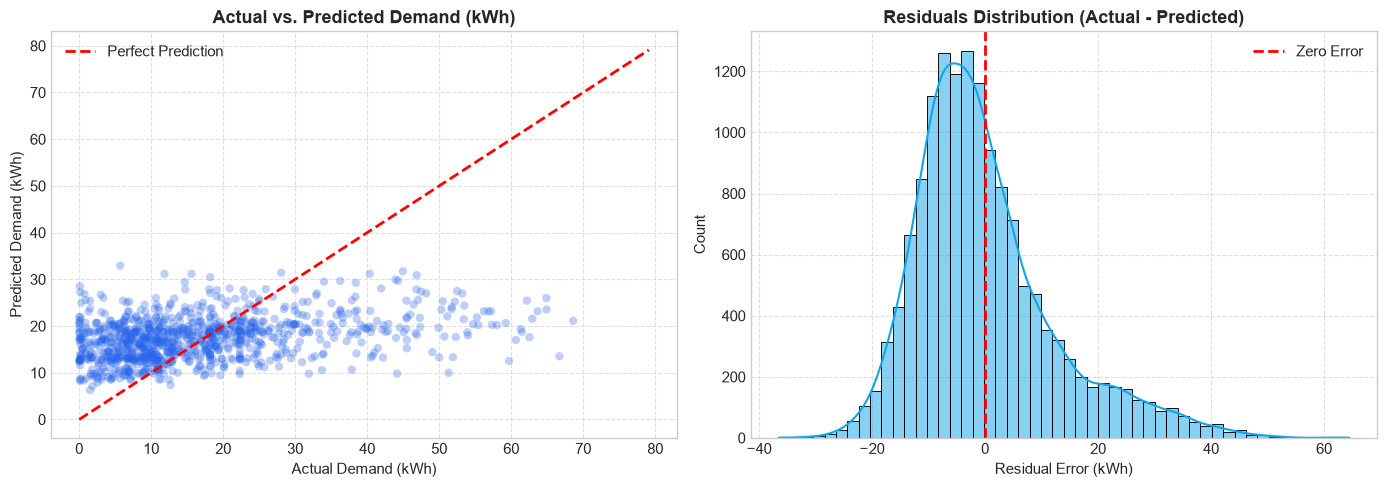

In [5]:
# Visualizations for Regression Model
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Actual vs Predicted (Subsample for clarity)
np.random.seed(42)
sample_indices = np.random.choice(len(y_test_reg), size=min(1000, len(y_test_reg)), replace=False)
axes[0].scatter(y_test_reg.iloc[sample_indices], y_pred_reg[sample_indices], alpha=0.3, color='#2563eb', edgecolors='none')
axes[0].plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'r--', lw=2, label='Perfect Prediction')
axes[0].set_title("Actual vs. Predicted Demand (kWh)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Actual Demand (kWh)")
axes[0].set_ylabel("Predicted Demand (kWh)")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot 2: Residuals Distribution
residuals = y_test_reg - y_pred_reg
sns.histplot(residuals, bins=50, kde=True, ax=axes[1], color='#0ea5e9')
axes[1].axvline(0, color='red', linestyle='--', lw=2, label='Zero Error')
axes[1].set_title("Residuals Distribution (Actual - Predicted)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Residual Error (kWh)")
axes[1].set_ylabel("Count")
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 5. Test Classification Model (`best_classification_model.pkl`)
Evaluate binary classification predicting whether session demand will exceed the high-demand threshold (`y_test_cls`).

In [6]:
# Generate predictions and probabilities
y_pred_cls = cls_pipeline.predict(X_test)
y_prob_cls = cls_pipeline.predict_proba(X_test)[:, 1]

# Calculate classification metrics
acc = accuracy_score(y_test_cls, y_pred_cls)
prec = precision_score(y_test_cls, y_pred_cls, zero_division=0)
rec = recall_score(y_test_cls, y_pred_cls, zero_division=0)
f1 = f1_score(y_test_cls, y_pred_cls, zero_division=0)
roc_auc = roc_auc_score(y_test_cls, y_prob_cls)

cls_metrics_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC Score'],
    'Value': [f"{acc:.4f} ({acc*100:.2f}%)", f"{prec:.4f}", f"{rec:.4f}", f"{f1:.4f}", f"{roc_auc:.4f}"],
    'Target': ['High (>0.60)', 'Balanced', 'High (>0.70)', 'Harmonic mean', 'Discriminative ability']
})

print("=" * 60)
print("  CLASSIFICATION MODEL EVALUATION SUMMARY")
print("=" * 60)
display(cls_metrics_df)

print("\nDetailed Classification Report:")
print(classification_report(y_test_cls, y_pred_cls, target_names=['Normal Demand', 'High Demand']))

# Sanity assertion
assert set(np.unique(y_pred_cls)).issubset({0, 1}), "Predictions must be binary {0, 1}!"
assert (y_prob_cls >= 0.0).all() and (y_prob_cls <= 1.0).all(), "Probabilities must be in [0, 1]!"
print("[PASS] Classification sanity assertions passed.")


  CLASSIFICATION MODEL EVALUATION SUMMARY


,Metric,Value,Target
0,Accuracy,0.6550 (65.50%),High (>0.60)
1,Precision,0.6351,Balanced
2,Recall,0.7206,High (>0.70)
3,F1-Score,0.6752,Harmonic mean
4,ROC-AUC Score,0.7165,Discriminative ability



Detailed Classification Report:
               precision    recall  f1-score   support

Normal Demand       0.68      0.59      0.63      7321
  High Demand       0.64      0.72      0.68      7248

     accuracy                           0.66     14569
    macro avg       0.66      0.66      0.65     14569
 weighted avg       0.66      0.66      0.65     14569

[PASS] Classification sanity assertions passed.


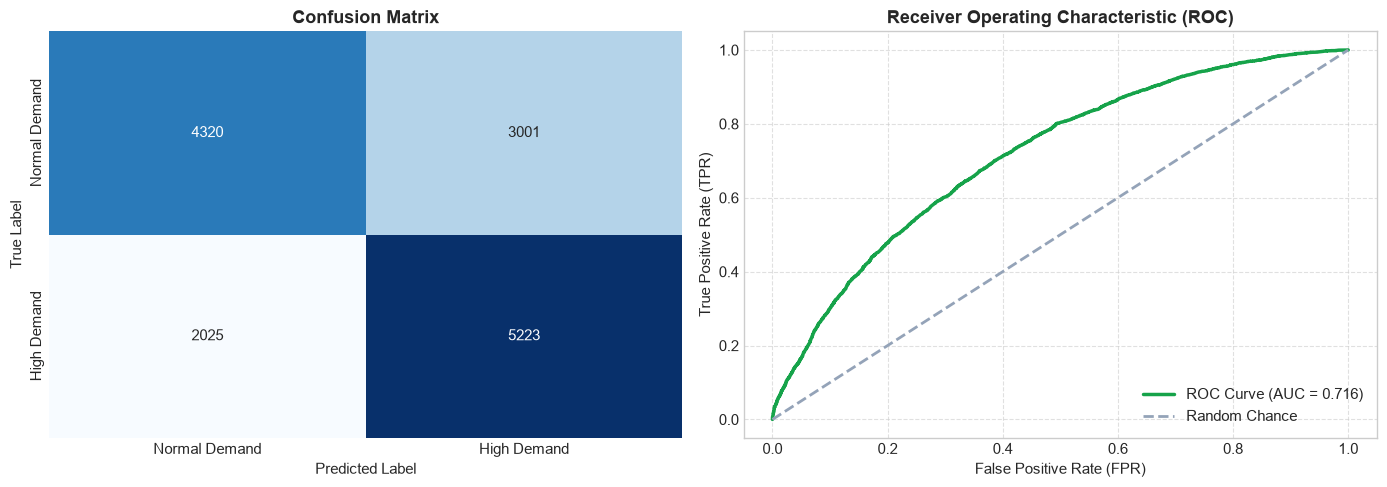

In [7]:
# Visualizations for Classification Model
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Confusion Matrix
cm = confusion_matrix(y_test_cls, y_pred_cls)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Normal Demand', 'High Demand'],
            yticklabels=['Normal Demand', 'High Demand'],
            cbar=False)
axes[0].set_title("Confusion Matrix", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# Plot 2: ROC Curve
fpr, tpr, _ = roc_curve(y_test_cls, y_prob_cls)
axes[1].plot(fpr, tpr, color='#16a34a', lw=2.5, label=f'ROC Curve (AUC = {roc_auc:.3f})')
axes[1].plot([0, 1], [0, 1], color='#94a3b8', linestyle='--', lw=2, label='Random Chance')
axes[1].set_title("Receiver Operating Characteristic (ROC)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("False Positive Rate (FPR)")
axes[1].set_ylabel("True Positive Rate (TPR)")
axes[1].legend(loc='lower right')
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 6. End-to-End Session Inference Function & Scenario Testing
A reusable function to test arbitrary session inputs through both models simultaneously.

In [8]:
def test_ev_session(session_dict):
    """
    Runs both regression and classification pipelines on a single charging session.
    """
    df_input = pd.DataFrame([session_dict])
    
    # Continuous Demand
    pred_demand = float(reg_pipeline.predict(df_input)[0])
    
    # Classification & Probability
    pred_class = int(cls_pipeline.predict(df_input)[0])
    prob_high = float(cls_pipeline.predict_proba(df_input)[0][1])
    
    category = "HIGH DEMAND" if pred_class == 1 else "NORMAL DEMAND"
    
    return {
        "Predicted Demand (kWh)": round(pred_demand, 2),
        "Threshold (kWh)": round(demand_threshold, 2),
        "Predicted Category": category,
        "High Demand Probability": f"{prob_high * 100:.1f}%",
        "Confidence Score": f"{max(prob_high, 1 - prob_high) * 100:.1f}%"
    }

# Test Scenarios
scenarios = [
    {
        "Scenario": "Corporate Fast DC - Peak Wednesday Afternoon",
        "Data": {
            "ChargerCompany": 1,
            "Location": "company",
            "ChargerType": 1,
            "StartHour": 14,
            "StartDayOfWeek": 2,
            "StartMonth": 6,
            "StartYear": 2022,
            "IsWeekend": 0,
            "TimePeriod": "Afternoon"
        }
    },
    {
        "Scenario": "Residential AC Slow - Sunday Late Night",
        "Data": {
            "ChargerCompany": 0,
            "Location": "apartment",
            "ChargerType": 0,
            "StartHour": 2,
            "StartDayOfWeek": 6,
            "StartMonth": 1,
            "StartYear": 2022,
            "IsWeekend": 1,
            "TimePeriod": "Night"
        }
    },
    {
        "Scenario": "Public Plaza Fast DC - Monday Morning Rush",
        "Data": {
            "ChargerCompany": 1,
            "Location": "public area",
            "ChargerType": 1,
            "StartHour": 8,
            "StartDayOfWeek": 0,
            "StartMonth": 9,
            "StartYear": 2022,
            "IsWeekend": 0,
            "TimePeriod": "Morning"
        }
    }
]

scenario_results = []
for s in scenarios:
    res = test_ev_session(s["Data"])
    res["Scenario"] = s["Scenario"]
    scenario_results.append(res)

df_scenario_results = pd.DataFrame(scenario_results)
cols = ["Scenario", "Predicted Demand (kWh)", "Predicted Category", "High Demand Probability", "Threshold (kWh)"]
display(df_scenario_results[cols])


,Scenario,Predicted Demand (kWh),Predicted Category,High Demand Probability,Threshold (kWh)
0,Corporate Fast DC - Peak Wednesday Afternoon,19.32,HIGH DEMAND,65.1%,14.11
1,Residential AC Slow - Sunday Late Night,21.66,NORMAL DEMAND,30.1%,14.11
2,Public Plaza Fast DC - Monday Morning Rush,20.13,HIGH DEMAND,67.8%,14.11


## 7. Automated Model Integrity Assertions
Run unit checks to certify model readiness for deployment.

In [9]:
# Suite of automated assertions
print("Running automated sanity tests...")

# 1. Output length matches input length
assert len(y_pred_reg) == len(X_test), "Regression prediction count does not match input length."
assert len(y_pred_cls) == len(X_test), "Classification prediction count does not match input length."

# 2. No nulls or infinities
assert not np.isnan(y_pred_reg).any(), "Regression predictions contain NaN values."
assert not np.isinf(y_pred_reg).any(), "Regression predictions contain Inf values."
assert not np.isnan(y_prob_cls).any(), "Probabilities contain NaN values."

# 3. Valid probability bounds [0, 1]
assert (y_prob_cls >= 0.0).all() and (y_prob_cls <= 1.0).all(), "Class probabilities out of [0, 1] range."

# 4. Binary output conformity
assert set(np.unique(y_pred_cls)).issubset({0, 1}), "Classification outputs must only be 0 or 1."

# 5. Sanity range for continuous predictions
assert (y_pred_reg > 0).all(), "Demand predictions must be positive."

print(" ALL 5 AUTOMATED INTEGRITY TESTS PASSED SUCCESSFULLY! ")


Running automated sanity tests...
 ALL 5 AUTOMATED INTEGRITY TESTS PASSED SUCCESSFULLY! 
